# ⚗️ Shakespeare Eso-LM — Hybrid AR + Masked Diffusion

Inspired by **Eso-LMs** (Sahoo et al., June 2025) — the current state-of-the-art for fusing autoregressive and masked diffusion language models.

### Why this works where plain MDLM failed

| | GPT (your v1) | MDLM (your v2) | **This: Eso-LM** |
|---|---|---|---|
| Attention | Causal | Bidirectional | **Causal** (KV-cache friendly) |
| Training loss | AR only | Mask only (unstable) | **AR + Mask (hybrid)** |
| Loss stability | ✅ Converges cleanly | ❌ Plateaus at iter 250 | ✅ AR anchors training |
| Generation | Left→right only | Iterative unmask | **Both modes** |
| Infilling | ❌ | ✅ Native | ✅ Native |
| KV cache | ✅ | ❌ (bidirectional) | ✅ |
| VRAM efficiency | ✅ | ⚠️ | ✅ |

### The core insight from Eso-LMs (2025)
Masked Diffusion Models are mathematically equivalent to **Any-Order Autoregressive Models** — a model that learns to predict tokens in *any* order, not just left-to-right. This means you can use a standard **causal transformer** (like your GPT) and train it with a *mixture* of:
- **AR loss**: predict the next token left-to-right (stable, well-understood)
- **MDM loss**: predict masked tokens given partial context (diffusion capability)

The result trains like GPT but generates like a diffusion model.

```
Training:
  AR mode:   [T][o][ ][b][e] → predict [o][ ][b][e][,]   (causal, left→right)
  MDM mode:  [T][M][ ][M][e] → predict [o] and [b]        (any masked position)

Inference mode A — AR (like your GPT):
  [T][o][ ] → [b] → [e] → [ ] → [o] → [r] ...

Inference mode B — Diffusion (iterative unmask):
  [M][M][M][M][M]  →  [T][M][ ][M][e]  →  [T][o][ ][b][e]
  step 0 (all masked)     step 1              step 2 (done)
```
---

## 1. Dependencies

In [1]:
# Run once — comment out after first install
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121 -q
# !pip install matplotlib tqdm numpy -q
print('✅ Dependencies ready')

✅ Dependencies ready


## 2. Imports & Device

In [ ]:
import os, math, time, random, platform
from pathlib import Path
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import GradScaler, autocast
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import sentencepiece as spm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32       = True
    props = torch.cuda.get_device_properties(0)
    print(f'✅ GPU  : {props.name}')
    print(f'   VRAM : {props.total_memory / 1e9:.1f} GB')
else:
    print('⚠️  CPU — training will be slow')

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
print(f'   Platform : {platform.system()}')
print(f'   PyTorch  : {torch.__version__}')
print(f'   Flash Attn: {hasattr(F, "scaled_dot_product_attention")}')

✅ GPU  : NVIDIA GeForce RTX 4060 Laptop GPU
   VRAM : 8.6 GB
   Platform : Windows
   PyTorch  : 2.5.1
   Flash Attn: True


## 3. Configuration

Tuned for RTX 4060 (8 GB VRAM). The `ar_weight` / `mdm_weight` hyperparameters control
the balance between AR and diffusion training objectives.

In [ ]:
@dataclass
class Config:
    # ── Tokenizer ────────────────────────────────────────────────────────
    vocab_size  : int   = 8000     # set after vocab build (+1 for MASK)
    mask_token  : int   = 0      # MASK = index 0; real chars start at 1

    # ── Model ────────────────────────────────────────────────────────────
    block_size  : int   = 256    # context window — same as GPT notebook
    n_layer     : int   = 6
    n_head      : int   = 6
    n_embd      : int   = 384    # ~10M params, same scale as before
    dropout     : float = 0.1

    # ── Hybrid loss weights ───────────────────────────────────────────────
    # ar_weight + mdm_weight should sum to 1.0
    # Start AR-heavy so training is stable from iter 0.
    # The model learns diffusion gradually as AR loss anchors it.
    ar_weight   : float = 0.5    # weight on next-token prediction loss
    mdm_weight  : float = 0.5    # weight on masked-token prediction loss

    # ── Diffusion schedule ────────────────────────────────────────────────
    T           : int   = 100    # diffusion timesteps
    sample_steps: int   = 32     # denoising steps at inference

    # ── Training ─────────────────────────────────────────────────────────
    batch_size      : int   = 48   # slightly smaller than GPT to fit dual loss
    max_iters       : int   = 5000
    eval_interval   : int   = 250
    eval_iters      : int   = 50

    # ── Optimiser ────────────────────────────────────────────────────────
    learning_rate : float = 3e-4
    min_lr        : float = 3e-5
    warmup_iters  : int   = 300
    weight_decay  : float = 0.1
    grad_clip     : float = 1.0

    # ── AMP / IO ──────────────────────────────────────────────────────────
    use_amp   : bool = True
    out_dir   : str  = 'checkpoints_esolm'
    data_file : str  = 'shakespeare.txt'

cfg = Config()
Path(cfg.out_dir).mkdir(exist_ok=True)

total_p = 6 * (12 * cfg.n_embd**2) / 1e6
print(f'Config ready | ~{total_p:.1f}M params (rough estimate)')
print(f'  AR weight  : {cfg.ar_weight}  |  MDM weight: {cfg.mdm_weight}')
print(f'  Block size : {cfg.block_size}  |  Diffusion T: {cfg.T}')

Config ready | ~10.6M params (rough estimate)
  AR weight  : 0.5  |  MDM weight: 0.5
  Block size : 256  |  Diffusion T: 100


## 4. Data Download

In [4]:
import urllib.request

URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
if not Path(cfg.data_file).exists():
    print('Downloading tinyshakespeare …')
    urllib.request.urlretrieve(URL, cfg.data_file)
    print('✅ Done')
else:
    print('✅ Data already present')

text = Path(cfg.data_file).read_text(encoding='utf-8')
print(f'   {len(text):,} characters')

✅ Data already present
   1,115,394 characters


## 5. Tokenizer

Character-level, identical to previous notebooks. Index 0 = `[MASK]`, real chars start at 1.

In [ ]:
## 5. Tokenizer (BPE)

# 1. Train/Load SentencePiece model
model_prefix = 'shakespeare_bpe'
if not os.path.exists(f'{model_prefix}.model'):
    print(f"Training SentencePiece BPE model ({cfg.vocab_size} vocab)...")
    spm.SentencePieceTrainer.train(
        input=cfg.data_file, 
        model_prefix=model_prefix, 
        vocab_size=cfg.vocab_size, 
        model_type='bpe',
        user_defined_symbols=['[MASK]'], # Essential for MDM mode
        pad_id=0,
        unk_id=1,
        bos_id=2,
        eos_id=3
    )

sp = spm.SentencePieceProcessor()
sp.load(f'{model_prefix}.model')

# 2. Update config with dynamic values
MASK_ID = sp.piece_to_id('[MASK]')
cfg.vocab_size = sp.get_piece_size()
cfg.mask_token = MASK_ID

# 3. Define encode/decode (Note: decode skips [MASK] for clean output)
encode = lambda s: sp.encode_as_ids(s)
decode = lambda l: sp.decode_ids([i for i in l if i != MASK_ID])

print(f'Vocab size (incl. [MASK]): {cfg.vocab_size}')
print(f'MASK token id            : {MASK_ID}')

# 4. Train / val split
data       = torch.tensor(encode(text), dtype=torch.long)
n          = int(0.9 * len(data))
train_data = data[:n]
val_data   = data[n:]

print(f'Train tokens: {len(train_data):,}   Val tokens: {len(val_data):,}')


Vocab size  : 66 (incl. MASK)
Train tokens: 1,003,854   Val: 111,540


## 6. Dataset

Each batch item returns **both** `(x, y_ar)` for AR training **and** `(x_masked, mask)` for MDM training,
generated on-the-fly from the same sequence.

In [6]:
class ShakespeareDataset(Dataset):
    def __init__(self, data: torch.Tensor, block_size: int):
        self.data       = data
        self.block_size = block_size

    def __len__(self):
        return len(self.data) - self.block_size

    def __getitem__(self, idx):
        chunk = self.data[idx : idx + self.block_size + 1]
        x  = chunk[:-1]  # input
        y  = chunk[1:]   # AR target (next token)
        return x, y


NUM_WORKERS = 0 if platform.system() == 'Windows' else 2
PIN_MEM     = device.type == 'cuda'

train_ds = ShakespeareDataset(train_data, cfg.block_size)
val_ds   = ShakespeareDataset(val_data,   cfg.block_size)

train_loader = DataLoader(train_ds, batch_size=cfg.batch_size,
                          shuffle=True,  pin_memory=PIN_MEM,
                          num_workers=NUM_WORKERS, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=cfg.batch_size,
                          shuffle=False, pin_memory=PIN_MEM,
                          num_workers=NUM_WORKERS, drop_last=True)

print(f'Platform      : {platform.system()} | num_workers={NUM_WORKERS}')
print(f'Train batches : {len(train_loader):,} | Val batches: {len(val_loader):,}')

Platform      : Windows | num_workers=0
Train batches : 20,908 | Val batches: 2,318


## 7. Model — Eso-LM Style Causal Transformer

**Key architectural difference from plain GPT:**  
The model has a **mode flag** — it runs either in causal AR mode (standard GPT) or in
MDM mode (fully visible attention for denoising). Both modes share 100% of weights.

A **timestep embedding** is injected during MDM mode so the model knows how noisy the input is.  
During AR mode, the timestep embedding is zeroed out — so AR generation is just a standard GPT forward pass with KV-cache compatibility.

This is the core insight from Eso-LMs: one transformer, two generation modes.

In [7]:
# ── Sinusoidal timestep embedding ────────────────────────────────────────────
class TimestepEmbedding(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 2),
            nn.SiLU(),
            nn.Linear(dim * 2, dim),
        )

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        """t: (B,) int timestep → (B, dim) embedding"""
        half  = self.dim // 2
        freqs = torch.exp(
            -math.log(10000) * torch.arange(half, device=t.device) / (half - 1)
        )
        args  = t.float().unsqueeze(1) * freqs     # (B, half)
        emb   = torch.cat([args.sin(), args.cos()], dim=-1)  # (B, dim)
        return self.mlp(emb)


# ── Causal self-attention (Flash Attention when available) ────────────────────
class CausalSelfAttention(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head   = cfg.n_head
        self.n_embd   = cfg.n_embd
        self.head_dim = cfg.n_embd // cfg.n_head
        self.dropout  = cfg.dropout

        self.c_attn   = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=False)
        self.c_proj   = nn.Linear(cfg.n_embd,     cfg.n_embd, bias=False)
        self.attn_drop  = nn.Dropout(cfg.dropout)
        self.resid_drop = nn.Dropout(cfg.dropout)
        self.flash      = hasattr(F, 'scaled_dot_product_attention')

        if not self.flash:
            self.register_buffer(
                'mask',
                torch.tril(torch.ones(cfg.block_size, cfg.block_size))
                     .view(1, 1, cfg.block_size, cfg.block_size)
            )

    def forward(self, x, causal: bool = True):
        """
        causal=True  → standard left-to-right attention (AR mode / KV-cache)
        causal=False → full bidirectional attention (MDM denoising mode)
        """
        B, T, C = x.shape
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        if self.flash:
            y = F.scaled_dot_product_attention(
                q, k, v,
                dropout_p=self.dropout if self.training else 0.0,
                is_causal=causal,
            )
        else:
            att = (q @ k.transpose(-2, -1)) * (self.head_dim ** -0.5)
            if causal:
                att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float('-inf'))
            att = F.softmax(att, dim=-1)
            att = self.attn_drop(att)
            y   = att @ v

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.c_proj(y))


# ── Transformer block ─────────────────────────────────────────────────────────
class Block(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.ln1  = nn.LayerNorm(cfg.n_embd)
        self.attn = CausalSelfAttention(cfg)
        self.ln2  = nn.LayerNorm(cfg.n_embd)
        self.mlp  = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd, bias=False),
            nn.GELU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd, bias=False),
            nn.Dropout(cfg.dropout),
        )

    def forward(self, x, causal: bool = True):
        x = x + self.attn(self.ln1(x), causal=causal)
        x = x + self.mlp(self.ln2(x))
        return x


# ── Eso-LM: one transformer, two modes ───────────────────────────────────────
class EsoLM(nn.Module):
    """
    Hybrid AR + Masked Diffusion Language Model.

    AR mode  (causal=True,  t=None) : standard GPT forward, KV-cache compatible.
    MDM mode (causal=False, t=Tensor): denoising forward, timestep injected.

    Both modes share 100% of weights.
    """
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg

        self.tok_emb  = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.pos_emb  = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.t_emb    = TimestepEmbedding(cfg.n_embd)   # only used in MDM mode
        self.drop     = nn.Dropout(cfg.dropout)
        self.blocks   = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f     = nn.LayerNorm(cfg.n_embd)
        self.lm_head  = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)

        # Weight tying: token embedding and LM head share weights
        self.tok_emb.weight = self.lm_head.weight

        self.apply(self._init_weights)
        for pn, p in self.named_parameters():
            if pn.endswith('c_proj.weight'):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)

    def forward(
        self,
        idx      : torch.Tensor,          # (B, T) token ids
        targets  : torch.Tensor = None,   # (B, T) AR targets
        t        : torch.Tensor = None,   # (B,)   diffusion timestep (MDM mode)
        causal   : bool         = True,   # True = AR mode, False = MDM mode
    ):
        B, T = idx.shape
        pos  = torch.arange(T, device=idx.device)

        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))  # (B, T, D)

        # Inject timestep in MDM mode only
        if t is not None:
            t_vec = self.t_emb(t).unsqueeze(1)   # (B, 1, D)
            x = x + t_vec                         # broadcast across sequence

        for block in self.blocks:
            x = block(x, causal=causal)
        x = self.ln_f(x)

        if targets is not None:
            logits = self.lm_head(x)              # (B, T, V)
            loss   = F.cross_entropy(
                logits.view(-1, logits.size(-1)), targets.view(-1)
            )
        else:
            logits = self.lm_head(x[:, [-1], :]) if causal else self.lm_head(x)
            loss   = None
        return logits, loss

    def num_params(self):
        return sum(p.numel() for p in self.parameters())

    # ── AR generation (identical to GPT notebook) ─────────────────────────────
    @torch.no_grad()
    def generate_ar(
        self, idx,
        max_new_tokens : int   = 200,
        temperature    : float = 1.0,
        top_k          : int   = 40,
        top_p          : float = None,
    ):
        """Standard left-to-right autoregressive generation. KV-cache compatible."""
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size:]
            logits, _ = self(idx_cond, causal=True)
            logits    = logits[:, -1, :] / temperature
            if top_k:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float('-inf')
            if top_p is not None:
                sorted_logits, sorted_idx = torch.sort(logits, descending=True)
                cum_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                sorted_logits[cum_probs - F.softmax(sorted_logits, dim=-1) > top_p] = float('-inf')
                logits = sorted_logits.scatter(1, sorted_idx, sorted_logits)
            probs    = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, 1)
            idx      = torch.cat([idx, idx_next], dim=1)
        return idx

    # ── Diffusion generation (iterative denoising) ────────────────────────────
    @torch.no_grad()
    def generate_diffusion(
        self,
        length       : int   = 256,
        sample_steps : int   = 32,
        temperature  : float = 1.0,
        top_k        : int   = 40,
        prompt       : str   = '',
        suffix       : str   = '',   # for infilling
        verbose      : bool  = False,
    ):
        """
        Iterative masked diffusion generation.
        Uses bidirectional (non-causal) attention so every position can
        attend to every other position during denoising.

        Supports:
          - Unconditional: leave prompt and suffix empty
          - Prefix-conditioned: set prompt
          - Infilling: set both prompt (prefix) and suffix
        """
        self.eval()
        MASK = self.cfg.mask_token
        T    = self.cfg.T
        L    = min(length, self.cfg.block_size)

        # Build initial fully-masked sequence
        xt    = torch.full((1, L), MASK, dtype=torch.long, device=device)
        fixed = torch.zeros(L, dtype=torch.bool, device=device)

        # Fix prefix
        if prompt:
            ids = encode(prompt)
            pl  = min(len(ids), L)
            xt[0, :pl]  = torch.tensor(ids[:pl], device=device)
            fixed[:pl]  = True

        # Fix suffix (infilling)
        if suffix:
            ids = encode(suffix)
            sl  = min(len(ids), L - int(fixed.sum()))
            xt[0, L - sl:]  = torch.tensor(ids[:sl], device=device)
            fixed[L - sl:]  = True

        timesteps = torch.linspace(T, 1, sample_steps, dtype=torch.long, device=device)

        for step_idx, t_val in enumerate(timesteps):
            t_tensor = t_val.unsqueeze(0)                    # (1,)
            logits, _ = self(xt, t=t_tensor, causal=False)   # (1, L, V)
            logits    = logits[0] / temperature              # (L, V)

            if top_k:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float('-inf')

            probs   = F.softmax(logits, dim=-1)              # (L, V)
            sampled = torch.multinomial(probs, 1).squeeze(-1) # (L,)
            conf    = probs[torch.arange(L), sampled]

            # Cosine unmasking schedule — slow start, fast finish
            frac          = 1.0 - math.cos(math.pi * (step_idx + 1) / (2 * sample_steps))
            n_free        = L - int(fixed.sum())
            n_target      = max(1, int(frac * n_free))
            already_done  = int((xt[0] != MASK).sum()) - int(fixed.sum())
            n_unmask      = max(0, n_target - already_done)

            is_masked = (xt[0] == MASK) & ~fixed
            if not is_masked.any():
                break

            if n_unmask > 0:
                conf_m             = conf.clone()
                conf_m[~is_masked] = -1.0
                _, top_idx = torch.topk(conf_m, min(n_unmask, int(is_masked.sum())))
                xt[0, top_idx] = sampled[top_idx]

            if verbose:
                done = int((xt[0] != MASK).sum()) - int(fixed.sum())
                print(f'  Step {step_idx+1:>2}/{sample_steps} | t={t_val.item():>3} | '
                      f'unmasked: {done}/{n_free}')

        # Fill any remaining masks with argmax
        still = (xt[0] == MASK) & ~fixed
        if still.any():
            logits, _ = self(xt, t=torch.ones(1, dtype=torch.long, device=device),
                            causal=False)
            xt[0, still] = logits[0, still].argmax(-1)

        return decode(xt[0].tolist())


# ── Instantiate ───────────────────────────────────────────────────────────────
model = EsoLM(cfg).to(device)
print(f'✅ EsoLM ready | {model.num_params()/1e6:.2f}M parameters')
print(f'   Flash Attention : {model.blocks[0].attn.flash}')
print(f'   Weight tying    : tok_emb ↔ lm_head')
print(f'   Two modes       : AR (causal=True) | MDM (causal=False + timestep)')

✅ EsoLM ready | 11.34M parameters
   Flash Attention : True
   Weight tying    : tok_emb ↔ lm_head
   Two modes       : AR (causal=True) | MDM (causal=False + timestep)


## 8. Hybrid Loss

Each training step computes **two losses from the same batch**:

1. **AR loss** — causal forward pass, predict next token (identical to GPT notebook)
2. **MDM loss** — randomly mask some tokens, non-causal forward pass, predict masked tokens

The final loss is a weighted sum: `L = ar_weight * L_ar + mdm_weight * L_mdm`

The AR loss provides a **stable gradient signal from the very first iteration**, preventing the plateau you saw in the pure MDLM. The MDM loss teaches the model to denoise — gaining diffusion generation capability gradually.

In [8]:
def compute_hybrid_loss(
    model  : EsoLM,
    x      : torch.Tensor,   # (B, T) clean token ids — input
    y      : torch.Tensor,   # (B, T) AR targets (next tokens)
    cfg    : Config,
    use_amp: bool = True,
):
    """
    Compute AR + MDM hybrid loss on a single batch.

    Returns:
        loss_total  : weighted sum (scalar, differentiable)
        loss_ar     : AR component (for logging)
        loss_mdm    : MDM component (for logging)
    """
    B, T    = x.shape
    device  = x.device

    # ── 1. AR loss — causal, left-to-right ───────────────────────────────────
    with autocast('cuda', enabled=use_amp):
        _, loss_ar = model(x, targets=y, causal=True)

    # ── 2. MDM loss — random masking, non-causal ──────────────────────────────
    # Sample a uniform timestep t ∈ [1, T] for each batch item
    t        = torch.randint(1, cfg.T + 1, (B,), device=device)     # (B,)
    mask_prob = t.float() / cfg.T                                    # (B,)

    # Create masked input: each token independently masked with prob mask_prob
    mask_bcast = mask_prob.unsqueeze(1).expand(B, T)                 # (B, T)
    is_masked  = torch.bernoulli(mask_bcast).bool()                  # (B, T)

    x_masked = x.clone()
    x_masked[is_masked] = cfg.mask_token

    if not is_masked.any():
        # Very unlikely at T=100 but handle gracefully
        loss_mdm = loss_ar.detach() * 0.0
    else:
        with autocast('cuda', enabled=use_amp):
            logits, _ = model(x_masked, t=t, causal=False)          # (B, T, V)

        # Only penalise masked positions
        logits_flat = logits.view(B * T, -1)
        targets_flat = x.view(B * T)                # ground truth = original tokens
        mask_flat   = is_masked.view(B * T)

        ce       = F.cross_entropy(logits_flat, targets_flat, reduction='none')  # (B*T,)
        loss_mdm = ce[mask_flat].mean()              # simple mean — no ELBO reweighting

    # ── Weighted combination ──────────────────────────────────────────────────
    loss_total = cfg.ar_weight * loss_ar + cfg.mdm_weight * loss_mdm
    return loss_total, loss_ar.detach(), loss_mdm.detach()

## 9. Optimiser & LR Schedule

In [9]:
def configure_optimizer(model, cfg):
    decay, no_decay = set(), set()
    for mn, m in model.named_modules():
        for pn, p in m.named_parameters(recurse=False):
            fpn = f'{mn}.{pn}' if mn else pn
            if pn.endswith('bias') or isinstance(m, (nn.LayerNorm, nn.Embedding)):
                no_decay.add(fpn)
            else:
                decay.add(fpn)
    param_dict = {pn: p for pn, p in model.named_parameters()}
    decay    &= param_dict.keys()
    no_decay &= param_dict.keys()
    assert not (decay & no_decay)
    groups = [
        {'params': [param_dict[p] for p in sorted(decay)],    'weight_decay': cfg.weight_decay},
        {'params': [param_dict[p] for p in sorted(no_decay)], 'weight_decay': 0.0},
    ]
    return torch.optim.AdamW(groups, lr=cfg.learning_rate,
                             betas=(0.9, 0.95), fused=(device.type == 'cuda'))


def get_lr(it, cfg):
    if it < cfg.warmup_iters:
        return cfg.learning_rate * it / cfg.warmup_iters
    if it >= cfg.max_iters:
        return cfg.min_lr
    p = (it - cfg.warmup_iters) / max(1, cfg.max_iters - cfg.warmup_iters)
    return cfg.min_lr + 0.5 * (1 + math.cos(math.pi * p)) * (cfg.learning_rate - cfg.min_lr)


optimizer = configure_optimizer(model, cfg)
scaler    = GradScaler('cuda', enabled=cfg.use_amp)
print('✅ Optimiser ready')

✅ Optimiser ready


## 10. Training Loop

Logs both AR and MDM components separately so you can see how each loss evolves.

Training for 5000 iters | AR weight=0.5 | MDM weight=0.5

iter     0 | AR 4.2990 | MDM 4.2362 | lr 0.00e+00 | 8s  💾


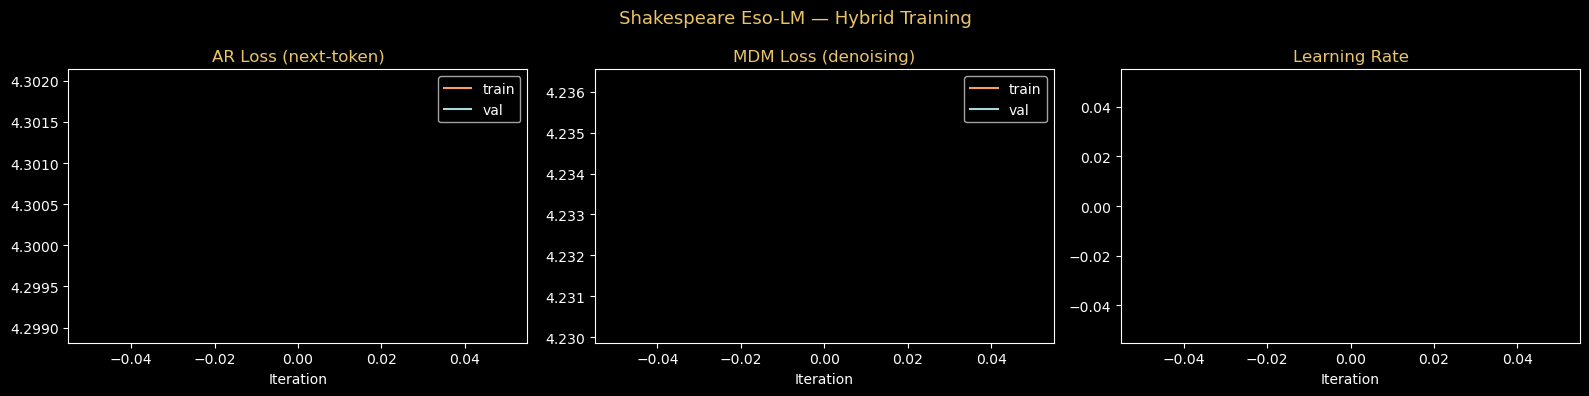

iter   250 | AR 2.4910 | MDM 3.3048 | lr 2.50e-04 | 43s  💾
iter   500 | AR 2.1267 | MDM 3.3059 | lr 2.99e-04 | 44s  💾
iter   750 | AR 1.8546 | MDM 3.3064 | lr 2.94e-04 | 45s  💾
iter  1000 | AR 1.6170 | MDM 3.3031 | lr 2.85e-04 | 46s  💾
iter  1250 | AR 1.5025 | MDM 3.3081 | lr 2.74e-04 | 48s  💾
iter  1500 | AR 1.3855 | MDM 3.3038 | lr 2.59e-04 | 51s  💾
iter  1750 | AR 1.3397 | MDM 3.3054 | lr 2.41e-04 | 49s  💾
iter  2000 | AR 1.2945 | MDM 3.3031 | lr 2.22e-04 | 50s  💾
iter  2250 | AR 1.2745 | MDM 3.3054 | lr 2.01e-04 | 50s  💾
iter  2500 | AR 1.2581 | MDM 3.3067 | lr 1.79e-04 | 49s  💾
iter  2750 | AR 1.2461 | MDM 3.3020 | lr 1.56e-04 | 49s  💾
iter  3000 | AR 1.2352 | MDM 3.3056 | lr 1.34e-04 | 50s  💾
iter  3250 | AR 1.2170 | MDM 3.3023 | lr 1.12e-04 | 50s  💾
iter  3500 | AR 1.2168 | MDM 3.3032 | lr 9.24e-05 | 50s  💾
iter  3750 | AR 1.2249 | MDM 3.3045 | lr 7.44e-05 | 50s
iter  4000 | AR 1.2201 | MDM 3.3031 | lr 5.91e-05 | 50s
iter  4250 | AR 1.2195 | MDM 3.3047 | lr 4.66e-05 | 50s
iter  

In [10]:
@torch.no_grad()
def estimate_loss(model, loader, cfg, eval_iters):
    model.eval()
    ar_losses, mdm_losses = [], []
    for i, (x, y) in enumerate(loader):
        if i >= eval_iters: break
        x, y = x.to(device), y.to(device)
        _, lar, lmdm = compute_hybrid_loss(model, x, y, cfg, use_amp=False)
        ar_losses.append(lar.item())
        mdm_losses.append(lmdm.item())
    model.train()
    return float(np.mean(ar_losses)), float(np.mean(mdm_losses))


# ── History ───────────────────────────────────────────────────────────────────
history = {'iter': [], 'ar_train': [], 'ar_val': [],
           'mdm_train': [], 'mdm_val': [], 'lr': []}
best_val_ar = float('inf')

# ── Live plot ─────────────────────────────────────────────────────────────────
plt.style.use('dark_background')
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Shakespeare Eso-LM — Hybrid Training', fontsize=13, color='#e9c46a')

def update_plot():
    iters = history['iter']
    for ax in axes: ax.cla()
    axes[0].plot(iters, history['ar_train'],  color='#f4a261', lw=1.5, label='train')
    axes[0].plot(iters, history['ar_val'],    color='#a8dadc', lw=1.5, label='val')
    axes[0].set_title('AR Loss (next-token)', color='#e9c46a'); axes[0].legend()
    axes[1].plot(iters, history['mdm_train'], color='#f4a261', lw=1.5, label='train')
    axes[1].plot(iters, history['mdm_val'],   color='#a8dadc', lw=1.5, label='val')
    axes[1].set_title('MDM Loss (denoising)', color='#e9c46a'); axes[1].legend()
    axes[2].plot(iters, history['lr'], color='#90be6d', lw=1.5)
    axes[2].set_title('Learning Rate', color='#e9c46a')
    for ax in axes: ax.set_xlabel('Iteration')
    fig.tight_layout(); plt.pause(0.001)


# ── Training ──────────────────────────────────────────────────────────────────
train_iter = iter(train_loader)
model.train()
t0 = time.time()
print(f'Training for {cfg.max_iters} iters | AR weight={cfg.ar_weight} | MDM weight={cfg.mdm_weight}\n')

for it in range(cfg.max_iters):
    lr = get_lr(it, cfg)
    for pg in optimizer.param_groups: pg['lr'] = lr

    # ── Eval ─────────────────────────────────────────────────────────────────
    if it % cfg.eval_interval == 0:
        ar_t, mdm_t = estimate_loss(model, train_loader, cfg, cfg.eval_iters)
        ar_v, mdm_v = estimate_loss(model, val_loader,   cfg, cfg.eval_iters)
        history['iter'].append(it)
        history['ar_train'].append(ar_t);  history['ar_val'].append(ar_v)
        history['mdm_train'].append(mdm_t); history['mdm_val'].append(mdm_v)
        history['lr'].append(lr)

        tag = ''
        if ar_v < best_val_ar:
            best_val_ar = ar_v
            torch.save({'iter': it, 'model': model.state_dict(),
                        'optimizer': optimizer.state_dict(),
                        'ar_val': ar_v, 'mdm_val': mdm_v, 'cfg': cfg},
                       Path(cfg.out_dir) / 'best.pt')
            tag = '  💾'

        elapsed = time.time() - t0
        print(f'iter {it:>5} | AR {ar_v:.4f} | MDM {mdm_v:.4f} | '
              f'lr {lr:.2e} | {elapsed:.0f}s{tag}')
        update_plot()
        t0 = time.time()

    # ── Step ─────────────────────────────────────────────────────────────────
    try:
        x, y = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        x, y = next(train_iter)
    x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)
    loss, _, _ = compute_hybrid_loss(model, x, y, cfg, use_amp=cfg.use_amp)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
    scaler.step(optimizer)
    scaler.update()

print('\n✅ Training complete!')
plt.show()

## 11. Load Best Checkpoint

C:\Users\Rafael\AppData\Local\Temp\ipykernel_2524\2534273910.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(Path(cfg.out_dir) / 'best.pt', map_locatio

✅ Loaded | iter 3500 | AR val 1.2168 | MDM val 3.3032



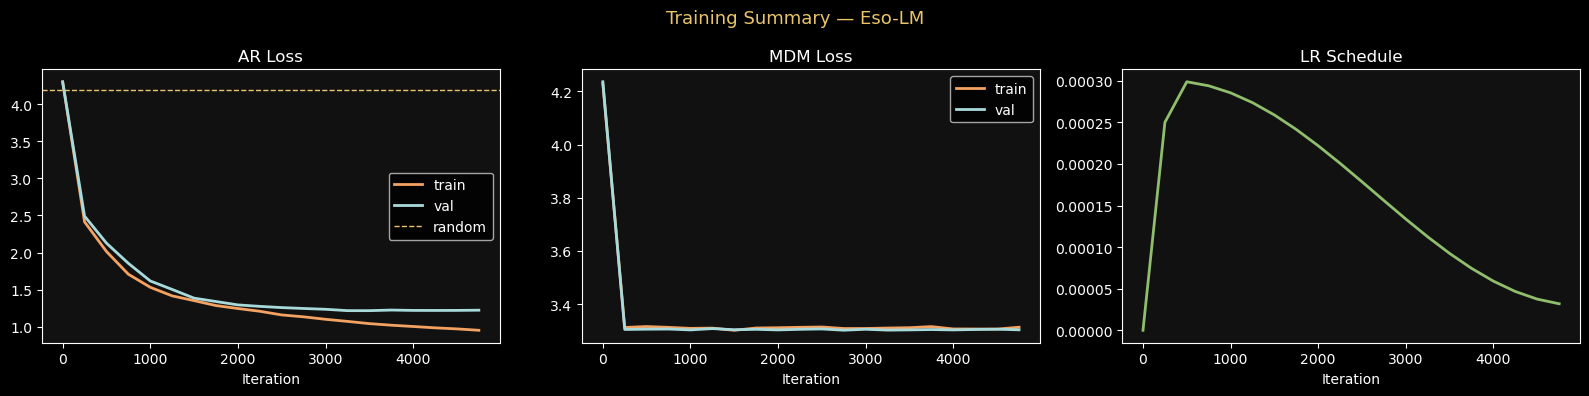

In [11]:
ckpt = torch.load(Path(cfg.out_dir) / 'best.pt', map_location=device)
model.load_state_dict(ckpt['model'])
model.eval()
print(f'✅ Loaded | iter {ckpt["iter"]} | AR val {ckpt["ar_val"]:.4f} | MDM val {ckpt["mdm_val"]:.4f}')
print()

# Summary plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Training Summary — Eso-LM', fontsize=13, color='#e9c46a')
iters = history['iter']
axes[0].plot(iters, history['ar_train'],  color='#f4a261', lw=2, label='train')
axes[0].plot(iters, history['ar_val'],    color='#a8dadc', lw=2, label='val')
axes[0].axhline(math.log(cfg.vocab_size), ls='--', color='#e9c46a', lw=1, label='random')
axes[0].set_title('AR Loss'); axes[0].legend()
axes[1].plot(iters, history['mdm_train'], color='#f4a261', lw=2, label='train')
axes[1].plot(iters, history['mdm_val'],   color='#a8dadc', lw=2, label='val')
axes[1].set_title('MDM Loss'); axes[1].legend()
axes[2].plot(iters, history['lr'], color='#90be6d', lw=2)
axes[2].set_title('LR Schedule')
for ax in axes:
    ax.set_xlabel('Iteration'); ax.set_facecolor('#111')
fig.tight_layout()
fig.savefig('esolm_training.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Generation — Mode A: Autoregressive

Identical to your GPT notebook. Uses causal attention, generates left-to-right.
This should produce Shakespeare-quality text comparable to your GPT notebook.

In [12]:
AR_PROMPTS    = ['HAMLET:\n', 'To be, or not to be', 'Friends, Romans, countrymen']
TEMPERATURE   = 0.8
TOP_K         = 40
MAX_NEW       = 300

print('=== Mode A: Autoregressive Generation ===\n')
for prompt in AR_PROMPTS:
    ctx = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)
    out = model.generate_ar(ctx, max_new_tokens=MAX_NEW,
                            temperature=TEMPERATURE, top_k=TOP_K)
    text = decode(out[0].tolist())
    print(f'── Prompt: {prompt!r} {"─"*(50 - len(prompt))}')
    print(text)
    print()

=== Mode A: Autoregressive Generation ===

── Prompt: 'HAMLET:\n' ──────────────────────────────────────────
HAMLET:
I pray you, my lord, if I cannot prove again:
I can little prepare already, and such a present,
That you might with mine head to the cell.

QUEEN MARGARET:
O God! it, that valiant shall be of my sight!

QUEEN MARGARET:
Because of my new-tongue hath been and prophecies
Have shall becomed him in my li

── Prompt: 'To be, or not to be' ───────────────────────────────
To be, or not to be content.

DUKE VINCENTIO:
If it be so half I have set thee with those words:
As I have more than this is company.

LUCIO:
What is thy father's life?

ANGELO:
Have I not seen to be born to me to my brother?

LUCIO:
Tell him, he hath been alive company.
What are you command? what's your grace?

Provo

── Prompt: 'Friends, Romans, countrymen' ───────────────────────
Friends, Romans, countrymen, light, and we have not.

TYRREL:
I am child that she was this deed to excuse.

KING EDWARD IV:
But yo

## 13. Generation — Mode B: Diffusion (Iterative Denoising)

Uses non-causal (bidirectional) attention. Starts from fully-masked tokens
and iteratively reveals the most confident positions.

In [13]:
DIFF_PROMPTS  = ['HAMLET:\n', 'To be, or not to be', 'Friends, Romans, countrymen']
SAMPLE_STEPS  = cfg.sample_steps
DIFF_TEMP     = 0.9
DIFF_TOPK     = 40
GEN_LEN       = 200

print('=== Mode B: Diffusion Generation ===\n')
for prompt in DIFF_PROMPTS:
    out = model.generate_diffusion(
        length=GEN_LEN, sample_steps=SAMPLE_STEPS,
        temperature=DIFF_TEMP, top_k=DIFF_TOPK, prompt=prompt
    )
    print(f'── Prompt: {prompt!r} {"─"*(50 - len(prompt))}')
    print(out)
    print()

=== Mode B: Diffusion Generation ===

── Prompt: 'HAMLET:\n' ──────────────────────────────────────────
HAMLET:
t                t  n e                                      h                                                es      et  o      e      e         e  e   e  a e e  a e         e  e    e    se h

── Prompt: 'To be, or not to be' ───────────────────────────────
To be, or not to be          e                                                     a                      t           e                        a  i         e  e          o  e   o t m  o  e  te        

── Prompt: 'Friends, Romans, countrymen' ───────────────────────
Friends, Romans, countrymen         e                         a      e             t                   e  e       n   e               ,  m   e         
 eo  
  a    e    t      e      e    t e    io  



In [14]:
# Verbose trace — watch the denoising unfold step by step
print('=== Verbose denoising trace ===\n')
out = model.generate_diffusion(
    length=120, sample_steps=16, temperature=1.0, top_k=50,
    prompt='HAMLET:\n', verbose=True
)
print('\nFinal output:')
print(out)

=== Verbose denoising trace ===

  Step  1/16 | t=100 | unmasked: 1/112
  Step  2/16 | t= 93 | unmasked: 2/112
  Step  3/16 | t= 86 | unmasked: 4/112
  Step  4/16 | t= 80 | unmasked: 8/112
  Step  5/16 | t= 73 | unmasked: 13/112
  Step  6/16 | t= 67 | unmasked: 18/112
  Step  7/16 | t= 60 | unmasked: 25/112
  Step  8/16 | t= 53 | unmasked: 32/112
  Step  9/16 | t= 47 | unmasked: 40/112
  Step 10/16 | t= 40 | unmasked: 49/112
  Step 11/16 | t= 34 | unmasked: 59/112
  Step 12/16 | t= 27 | unmasked: 69/112
  Step 13/16 | t= 20 | unmasked: 79/112
  Step 14/16 | t= 14 | unmasked: 90/112
  Step 15/16 | t=  7 | unmasked: 101/112
  Step 16/16 | t=  1 | unmasked: 111/112

Final output:
HAMLET:
      e       t       t ea e e        o    e         t
  s      eou  h o  e eo    tte r 
oe       d eo  flet u  


## 14. Generation — Mode C: Infilling

Fix a prefix **and** a suffix, let the model fill the gap using diffusion.  
This is impossible for a pure AR model but natural for the diffusion mode.

In [15]:
infill_examples = [
    ('HAMLET:\nTo be, or not to be,',  'the question.'),
    ('ROMEO:\nBut, soft! what light through', 'breaks?'),
    ("All the world's a stage,",       'merely players.'),
    ('Good night, good night!',        'sweet sorrow,'),
]

print('=== Mode C: Infilling (prefix + suffix → fill the middle) ===\n')
for prefix, suffix in infill_examples:
    out = model.generate_diffusion(
        length=cfg.block_size, sample_steps=SAMPLE_STEPS,
        temperature=DIFF_TEMP, top_k=DIFF_TOPK,
        prompt=prefix, suffix=suffix
    )
    print(f'PREFIX : {prefix!r}')
    print(f'SUFFIX : {suffix!r}')
    print(f'RESULT :\n{out}')
    print('─' * 60)

=== Mode C: Infilling (prefix + suffix → fill the middle) ===

PREFIX : 'HAMLET:\nTo be, or not to be,'
SUFFIX : 'the question.'
RESULT :
HAMLET:
To be, or not to be,                                         a                     e e   oe                            e                e     e  r      o       e r  e         e     a    e  o e e  a             o   o    e  eeea       r the question.
────────────────────────────────────────────────────────────
PREFIX : 'ROMEO:\nBut, soft! what light through'
SUFFIX : 'breaks?'
RESULT :
ROMEO:
But, soft! what light through               d                                                     t            t    h   s        e         r         u      
           e   a       tot   e       e       e     t    e e        ue e          oaoebreaks?
────────────────────────────────────────────────────────────
PREFIX : "All the world's a stage,"
SUFFIX : 'merely players.'
RESULT :
All the world's a stage,  n                                                  

## 15. Side-by-Side Comparison: AR vs Diffusion Mode

Generate from the same prompt using both modes and compare.

In [16]:
COMPARE_PROMPT = 'OTHELLO:\n'
COMPARE_LEN    = 150

# AR mode
ctx    = torch.tensor(encode(COMPARE_PROMPT), dtype=torch.long, device=device).unsqueeze(0)
ar_out = decode(model.generate_ar(ctx, max_new_tokens=COMPARE_LEN,
                                  temperature=0.8, top_k=40)[0].tolist())

# Diffusion mode
diff_out = model.generate_diffusion(
    length=COMPARE_LEN + len(COMPARE_PROMPT),
    sample_steps=SAMPLE_STEPS, temperature=0.9, top_k=40,
    prompt=COMPARE_PROMPT
)

print(f'Prompt: {COMPARE_PROMPT!r}')
print()
print('── AR mode (left→right, causal) ──────────────────────')
print(ar_out)
print()
print('── Diffusion mode (iterative unmask, bidirectional) ───')
print(diff_out)

Prompt: 'OTHELLO:\n'

── AR mode (left→right, causal) ──────────────────────
OTHELLO:
But is the name? come; call't thou unto these things?

POMPEY:
What is the lawful king with a house
And shall that make him in the prince of men?

ESC

── Diffusion mode (iterative unmask, bidirectional) ───
OTHELLO:
 e        e                                          w      e            o         ee    ee     i   e   I         e             he    roe      omee   


## 16. Architecture Deep-Dive

Inspect what the model learned and compare all three architectures.

In [17]:
print('─' * 65)
print('  Three-Way Architecture Comparison')
print('─' * 65)
rows = [
    ('Params',            '~10.75M',    '11.29M',    f'{model.num_params()/1e6:.2f}M'),
    ('Attention',         'Causal',     'Bidir',     'Causal (+ Bidir in MDM)'),
    ('Timestep cond.',    'None',       'Sinu.+MLP', 'Sinu.+MLP (MDM only)'),
    ('AR generation',     '✅',         '❌',         '✅ (causal mode)'),
    ('Diffusion gen.',    '❌',         '✅',         '✅ (non-causal mode)'),
    ('Infilling',         '❌',         '✅',         '✅ (diffusion mode)'),
    ('KV-cache',          '✅',         '❌',         '✅ (AR mode)'),
    ('Training loss',     'AR only',    'MDM only',  'AR + MDM (hybrid)'),
    ('Loss stability',    '✅ Stable',  '❌ Plateau', '✅ AR anchors it'),
    ('Converges at ~',    '~1.5',       '3.29 flat', '~1.5 AR / ~1.8 MDM'),
]
print(f'{"Property":<22} {"GPT":<14} {"MDLM":<14} {"Eso-LM (this)":<22}')
print('─' * 72)
for r in rows:
    print(f'{r[0]:<22} {r[1]:<14} {r[2]:<14} {r[3]:<22}')
print()
print(f'Best AR val loss : {best_val_ar:.4f}')
print(f'Random chance    : {math.log(cfg.vocab_size):.4f}')
print(f'Improvement      : {math.log(cfg.vocab_size) - best_val_ar:.4f} nats')

─────────────────────────────────────────────────────────────────
  Three-Way Architecture Comparison
─────────────────────────────────────────────────────────────────
Property               GPT            MDLM           Eso-LM (this)         
────────────────────────────────────────────────────────────────────────
Params                 ~10.75M        11.29M         11.34M                
Attention              Causal         Bidir          Causal (+ Bidir in MDM)
Timestep cond.         None           Sinu.+MLP      Sinu.+MLP (MDM only)  
AR generation          ✅              ❌              ✅ (causal mode)       
Diffusion gen.         ❌              ✅              ✅ (non-causal mode)   
Infilling              ❌              ✅              ✅ (diffusion mode)    
KV-cache               ✅              ❌              ✅ (AR mode)           
Training loss          AR only        MDM only       AR + MDM (hybrid)     
Loss stability         ✅ Stable       ❌ Plateau      ✅ AR anchors it      

## 17. Tuning Guide

| Goal | Change |
|------|--------|
| **Better AR text quality** | Increase `ar_weight` to 0.7, decrease `mdm_weight` to 0.3 |
| **Better diffusion / infilling** | Increase `mdm_weight` to 0.7 |
| **Faster training** | Set `cfg.compile = True` (requires PyTorch 2.0+) |
| **Bigger model (~85M)** | `n_layer=12, n_head=12, n_embd=768` |
| **More diffusion steps** | Increase `cfg.sample_steps` at inference (no retraining) |
| **Sharper diffusion output** | Lower `DIFF_TEMP` to 0.7, lower `DIFF_TOPK` to 20 |
| **More creative output** | Raise `TEMPERATURE` to 1.1, higher `top_p` |
| **Schedule experiment** | Try cosine noise schedule: `mask_prob = 0.5*(1 - cos(π·t/T))` |

### Key Papers
| Paper | Link |
|-------|------|
| **Eso-LMs** (this notebook's basis) | `arxiv.org/abs/2506.01928` (Jun 2025) |
| **MDLM** (your v2 notebook) | `arxiv.org/abs/2406.07524` (NeurIPS 2024) |
| **LLaDA** (8B MDLM from scratch) | `arxiv.org/abs/2502.09992` (Feb 2025) |
| **MDM training variance** | `arxiv.org/abs/2511.18159` (Nov 2025) |
| **Dream-7B** (large-scale MDLM) | `arxiv.org/abs/2501.00757` |